# 29｜复杂场景与拒判

目标：看见一个可重复运行的算法如何在真实遮挡和反光中失败，并设计黄色待复核路径。下面是真实螺钉盒照片，存在重叠、局部遮挡、反光和复杂背景。没有完整零件数量真值，所以只输出候选区域数，不编造计数准确率。

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "course_utils.py").is_file())
INDUSTRIAL_ROOT = ROOT / "courses" / "industrial-vision-lab"
if str(INDUSTRIAL_ROOT) not in sys.path:
    sys.path.insert(0, str(INDUSTRIAL_ROOT))
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
import lab_utils as lab
print("OpenCV", cv2.__version__, "| NumPy", np.__version__)

OpenCV 4.12.0 | NumPy 2.2.6


/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 23454 (\N{CJK UNIFIED IDEOGRAPH-5B9E}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 36974 (\N{CJK UNIFIED IDEOGRAPH-906E}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 25377 (\N{CJK UNIFIED IDEOGRAPH-6321}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 34746 (\N{CJK UNIFIED IDEOGRAPH-87BA}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/

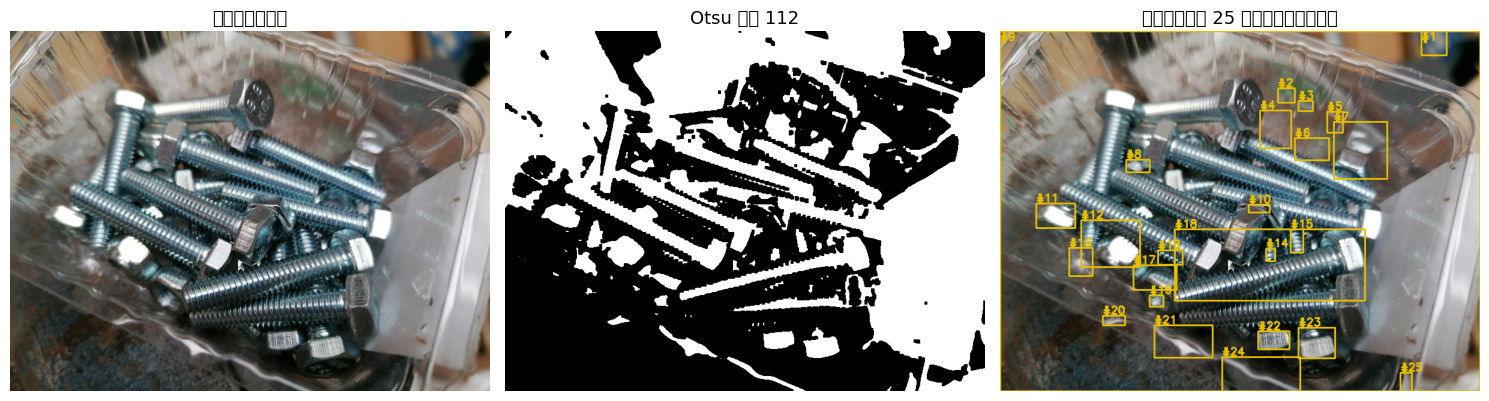

{'status': 'REVIEW', 'observed_regions': 25, 'true_count': None, 'reason': '遮挡和反光，尚无逐件真值，不能确认全数检出'}


In [2]:
image = lab.load_case("parts_occluded")
image = cv2.resize(image, (800, 600), interpolation=cv2.INTER_AREA)
g = lab.gray(image)
smooth = cv2.GaussianBlur(g, (5, 5), 0)
otsu_value, binary = cv2.threshold(smooth, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
closed = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
candidates = lab.component_boxes(closed, min_area=150)
lab.show_images([image, closed, lab.draw_boxes(image, candidates)],
                ["真实遮挡螺钉盒", f"Otsu 阈值 {otsu_value:.0f}", f"只有候选区域 {len(candidates)} 个，不等于物理数量"], cols=3)
print({"status": "REVIEW", "observed_regions": len(candidates), "true_count": None,
       "reason": "遮挡和反光，尚无逐件真值，不能确认全数检出"})

## 1. 画质门控需要在任务 ROI 标定

下面阈值是教学示例，不是工厂通用标准。模糊可能使清晰度下降，噪声也可能使其上升。质量通过表示“值得继续判断”，并不表示焊接合格。边界出画、遮挡和未知七格仍要单独拒判。

In [3]:
def quality_gate(roi):
    q = lab.image_quality(roi)
    reasons = []
    if q["dark_ratio"] > 0.35: reasons.append("过暗比例过高")
    if q["overexposed_ratio"] > 0.20: reasons.append("过曝比例过高")
    if q["sharpness"] < 35: reasons.append("缺少清晰纹理，需检查对焦或曝光")
    return {"eligible": not reasons, "status": "REVIEW", "quality": q,
            "reason": "；".join(reasons) if reasons else "画质门控通过，仍需工件与七格检查"}

real = lab.load_case("weld_good")
challenges = [real, lab.degrade(real, 0.08), lab.degrade(real, 1.8), lab.degrade(real, 0.7, blur=25)]
for label, candidate in zip(["实拍参考", "派生过暗", "派生过亮", "派生模糊"], challenges):
    print(label, quality_gate(candidate))
assert quality_gate(challenges[1])["eligible"] is False

实拍参考 {'eligible': True, 'status': 'REVIEW', 'quality': {'brightness': 48.829, 'sharpness': 207.265, 'dark_ratio': 0.33159, 'overexposed_ratio': 0.00843, 'width': 640, 'height': 640}, 'reason': '画质门控通过，仍需工件与七格检查'}
派生过暗 {'eligible': False, 'status': 'REVIEW', 'quality': {'brightness': 3.444, 'sharpness': 2.484, 'dark_ratio': 0.99326, 'overexposed_ratio': 0.0, 'width': 640, 'height': 640}, 'reason': '过暗比例过高；缺少清晰纹理，需检查对焦或曝光'}
派生过亮 {'eligible': True, 'status': 'REVIEW', 'quality': {'brightness': 81.076, 'sharpness': 473.054, 'dark_ratio': 0.16468, 'overexposed_ratio': 0.08216, 'width': 640, 'height': 640}, 'reason': '画质门控通过，仍需工件与七格检查'}
派生模糊 {'eligible': False, 'status': 'REVIEW', 'quality': {'brightness': 33.709, 'sharpness': 1.237, 'dark_ratio': 0.45768, 'overexposed_ratio': 0.0, 'width': 640, 'height': 640}, 'reason': '过暗比例过高；缺少清晰纹理，需检查对焦或曝光'}


## 2. 看“错误绿灯”更重要

假设焊格算法在模糊图上仍返回七个 OK，前置画质门控应拦下。这是控制流程测试，不是视觉识别成绩。实际评估要分别记漏检、误检、错误放行、不必要拒判，以及处理延迟。

In [4]:
fake_slots = ["OK"] * 7  # 明确：这里是流程测试输入，不是假装模型输出
quality_result = quality_gate(challenges[1])
decision = lab.seven_slot_verdict(fake_slots, quality_clear=quality_result["eligible"])
display(decision)
assert decision["status"] == "REVIEW"

{'good_count': 7,
 'required_good': 5,
 'total_slots': 7,
 'slots': ['OK', 'OK', 'OK', 'OK', 'OK', 'OK', 'OK'],
 'status': 'REVIEW',
 'reason': '工件不完整或画质不满足判读条件'}

## 最小现场验收表

每个新物理样本保留原图、逐件汇流排框、镍片存在性、七格人工标签、光照/角度、结果与原因。按来源分组冻结验收集，不能看完错例再在同一集上反复调参并称独立成绩。对“至少 90%”必须先确认口径是逐格、逐镍片还是整帧，以及黄色如何计入。

## 来源与练习边界

公开焊缝：sukmaadhiwijaya / rikkarth，固定提交 `8b80d1afe88c0b946500a498cbdb9d7a1eda5533`，数据卡声明 CC0-1.0；工业表面：Kolektor Group / ViCoS，CC BY-NC-SA 4.0；分散零件：Tung1213，CC BY-SA 3.0；重叠零件：Technologyfelix，CC BY-SA 4.0。相关照片和派生图保留原许可及署名。

完整来源、原许可页、下载路径及 SHA256 见 [DATA_SOURCES.md](../DATA_SOURCES.md) 和 [source_manifest.json](../sources/source_manifest.json)。本课是非商业教学。灰度、二值、叠框及扰动均为原照片的派生图，七格合成图另有醒目标记。它们不等于新增独立验收数据，也不证明电池焊接准确率或机械强度。